# FleetLogix | Proyecto Integrador — Avance 3

## Data Warehouse en Snowflake y pipeline ETL desde PostgreSQL

**Módulo:** Data Science — Proyecto Integrador  
**Etapa:** Avance 3 — Modelado dimensional, integración de datos, calidad y gobernanza  
**Tecnologías:** PostgreSQL, Snowflake, Python, Pandas, `psycopg2`, `snowflake-connector-python`, `schedule`  
**Estado del proyecto:** modelo y carga inicial implementados y comprobados; automatización integral e historial SCD2 pendientes de una prueba funcional completa (ver [Estado de las verificaciones](#estado-de-las-verificaciones)).

> **Alcance y trazabilidad.** Este documento describe **nuestro entorno FleetLogix**, no el de otros estudiantes. Las cifras que se indican como verificadas proceden de las pruebas realizadas sobre nuestra base PostgreSQL y nuestro esquema de Snowflake. No se presentan resultados simulados como mediciones reales. Las definiciones de tablas y vistas se recuperaron de Snowflake con `GET_DDL`.

---

## 1. Objetivo del avance

Transformar los datos transaccionales de una operación logística en un **Data Warehouse analítico** que permita responder preguntas sobre entregas, puntualidad, recorridos, combustible, conductores y vehículos.

Los objetivos técnicos son:

1. Diseñar un **modelo dimensional en estrella** con un grano de negocio definido.
2. Extraer información de PostgreSQL, transformarla y cargarla en Snowflake mediante un ETL en Python.
3. Implementar mecanismos para cargas repetibles, control de calidad, historial de conductores y consultas agregadas.
4. Aplicar controles de acceso mediante vistas seguras y roles, además de retención histórica mediante Time Travel.
5. Documentar las comprobaciones, las limitaciones del origen y la arquitectura de una futura operación automática.

## 2. Origen de datos: PostgreSQL (OLTP)

El origen es la base local **`fleetlogix`**, con seis tablas relacionadas.

| Tabla | Registros observados | Función en la operación |
|---|---:|---|
| `vehicles` | 200 | Datos maestros de vehículos y capacidad |
| `drivers` | 400 | Conductores y sus atributos operativos |
| `routes` | 50 | Origen, destino, distancia y peajes de rutas |
| `trips` | 100.000 | Viajes que relacionan conductor, vehículo y ruta |
| `deliveries` | 400.000 | Entregas vinculadas a viajes |
| `maintenance` | 5.000 | Historial de mantenimientos de vehículos |
| **Total** | **505.650** | **Registros en el modelo transaccional** |

**Relaciones principales:** `deliveries.trip_id` → `trips.trip_id`; `trips.vehicle_id` → `vehicles.vehicle_id`; `trips.driver_id` → `drivers.driver_id`; `trips.route_id` → `routes.route_id`. La tabla `maintenance` pertenece al origen, aunque no se incorporó como dimensión separada en esta versión del Data Warehouse.

### Diferencia entre OLTP y OLAP

| PostgreSQL — operacional (OLTP) | Snowflake — analítico (OLAP) |
|---|---|
| Registra viajes, entregas y datos maestros | Consolida entregas para análisis histórico |
| Modelo relacional normalizado | Modelo en estrella con hechos y dimensiones |
| Consultas operativas e inserciones frecuentes | Consultas agregadas por fecha, conductor, ruta o vehículo |
| Estado disponible en las tablas actuales | Preparación para historial SCD2, agregados y Time Travel |

### Evidencia visual: modelo relacional de origen

El siguiente diagrama documenta las seis tablas PostgreSQL del proyecto. Está **incrustado en el notebook** y se muestra sin ejecutar Python.

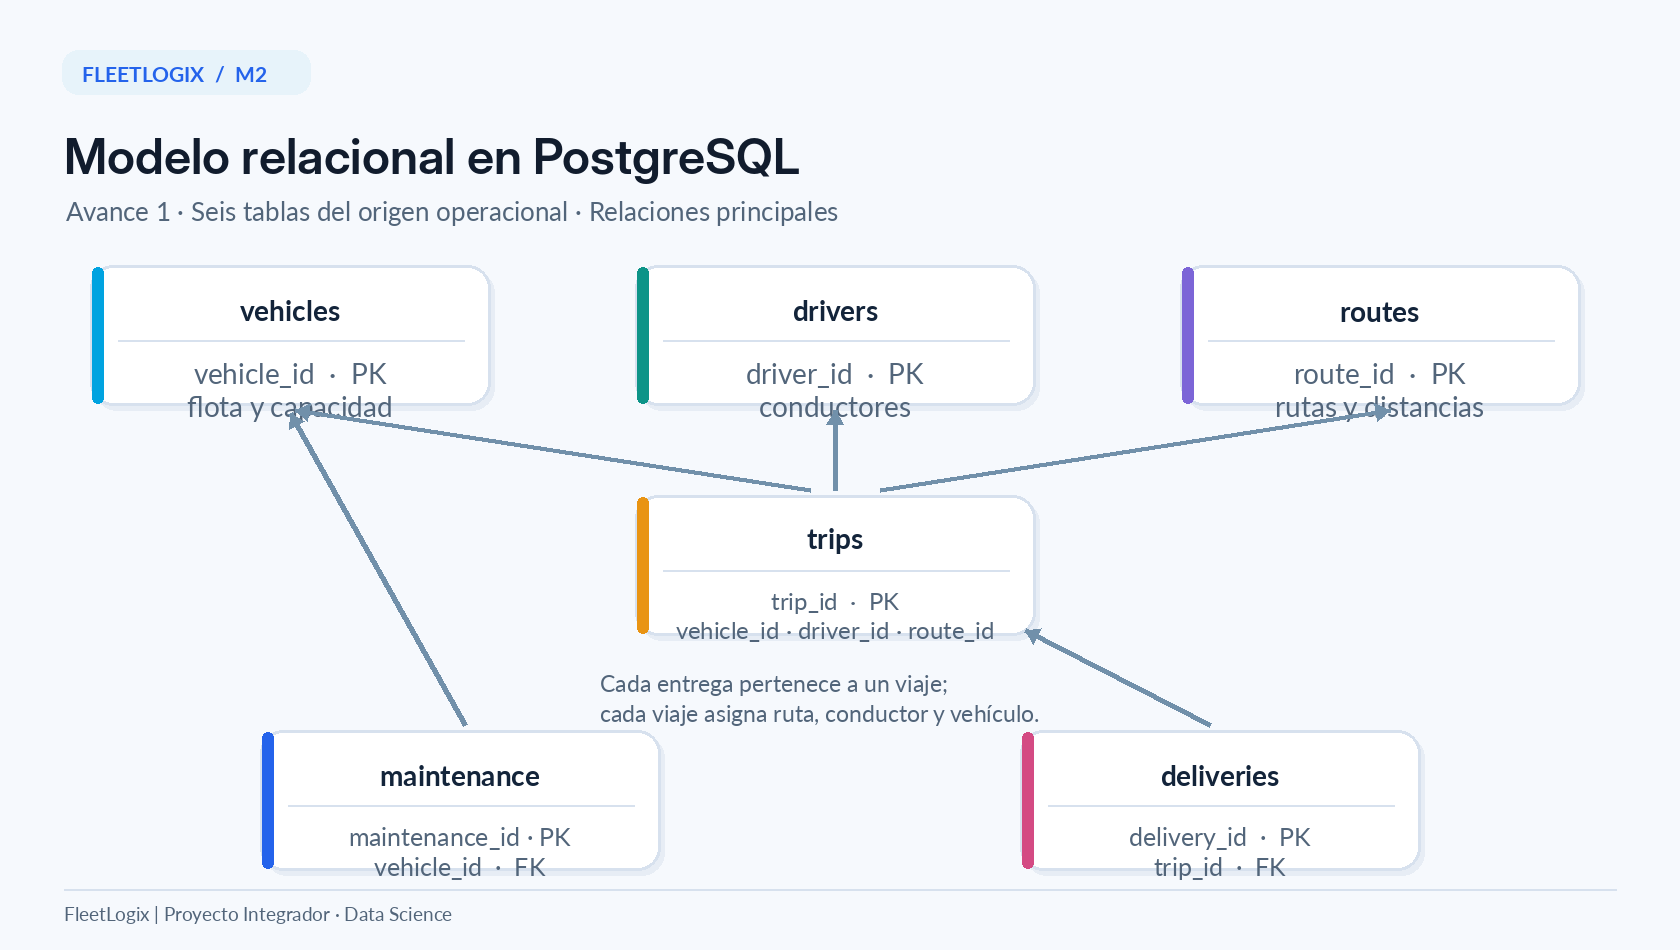

In [ ]:
# Figura incorporada como salida permanente del notebook.
# No hace falta ejecutar esta celda para ver el diagrama.

## 3. Diseño dimensional: esquema en estrella

**Grano de `FACT_DELIVERIES`: una fila por entrega completada, identificada por `DELIVERY_ID`.** No se utiliza una fila por viaje, pues un viaje puede contener varias entregas.

```mermaid
flowchart TB
    DD["DIM_DATE<br/>Fecha y calendario"] --> F["FACT_DELIVERIES<br/>Una fila por entrega completada"]
    DT["DIM_TIME<br/>Hora de entrega"] --> F
    DV["DIM_VEHICLE<br/>Vehículo"] --> F
    DR["DIM_DRIVER<br/>Conductor y vigencia SCD2"] --> F
    RT["DIM_ROUTE<br/>Ruta y distancia"] --> F
    DC["DIM_CUSTOMER<br/>Cliente + dirección"] --> F
    F --> AG["AGG_ENTREGAS_HORA<br/>Indicadores por fecha, hora y conductor"]
```

*Diagrama conceptual; las flechas representan asociaciones analíticas por las claves de las dimensiones, no necesariamente claves foráneas físicas aplicadas por Snowflake.*

### 3.1. Dimensiones

| Dimensión | Clave de unión | Atributos y observaciones |
|---|---|---|
| `DIM_DATE` | `DATE_KEY` | Fecha, año, trimestre, mes, día de semana y fin de semana; `IS_HOLIDAY` sin calendario oficial |
| `DIM_TIME` | `TIME_KEY` | Una fila por hora, de 0 a 23; **granularidad horaria**, no por minuto |
| `DIM_VEHICLE` | `VEHICLE_KEY` | ID de vehículo, patente, tipo, capacidad, combustible, adquisición y estado |
| `DIM_DRIVER` | `DRIVER_KEY` | ID de conductor, código, nombre, licencia, fecha de ingreso, estado y columnas de vigencia histórica |
| `DIM_ROUTE` | `ROUTE_KEY` | ID y código de ruta, ciudades, kilómetros, duración estimada y peajes |
| `DIM_CUSTOMER` | `CUSTOMER_KEY` | Hash SHA-256 de la combinación normalizada nombre + dirección de entrega |

La clave de cliente identifica la **combinación nombre–dirección**, no una identidad personal validada. Por ello, el número de filas de `DIM_CUSTOMER` no debe interpretarse automáticamente como número de personas únicas.

### 3.2. Hechos y medidas

`FACT_DELIVERIES` contiene `DELIVERY_ID`, `TRIP_ID`, las claves de las seis dimensiones, las marcas de tiempo programada y real, más las siguientes métricas:

| Campo | Regla de cálculo o interpretación |
|---|---|
| `DELIVERY_DURATION_MINUTES` | Minutos entre salida del viaje y entrega real; se rechazan duraciones negativas y anomalías extremas |
| `DISTANCE_KM` | Distancia del viaje distribuida proporcionalmente entre entregas según el peso del paquete |
| `FUEL_CONSUMED_LITERS` | Combustible del viaje repartido con la misma regla |
| `PACKAGE_WEIGHT_KG` | Peso informado en la entrega original |
| `IS_ON_TIME` | `DELIVERED_DATETIME <= SCHEDULED_DATETIME`; no se aplica tolerancia adicional |
| `REVENUE_ESTIMATED` | `NULL`: el origen **no proporciona** precios ni ingresos comprobables |
| `LOAD_TIMESTAMP` | Momento en que Snowflake registra la carga |

**Justificación de las asignaciones proporcionales.** Si cada entrega recibiera todos los kilómetros y todo el combustible de su viaje, sumar por ruta o conductor multiplicaría esas magnitudes. El ETL utiliza la proporción `peso_entrega / peso_total_del_viaje`; cuando no hay peso positivo utilizable, distribuye en partes iguales. Es una **estimación de asignación**, no un sensor que mida consumo por paquete.

### Esquema estrella — figura incorporada

La figura siguiente representa el grano y las seis dimensiones descritas en esta sección. **Es una visualización documental del modelo**, no una captura de ejecución en Snowflake.

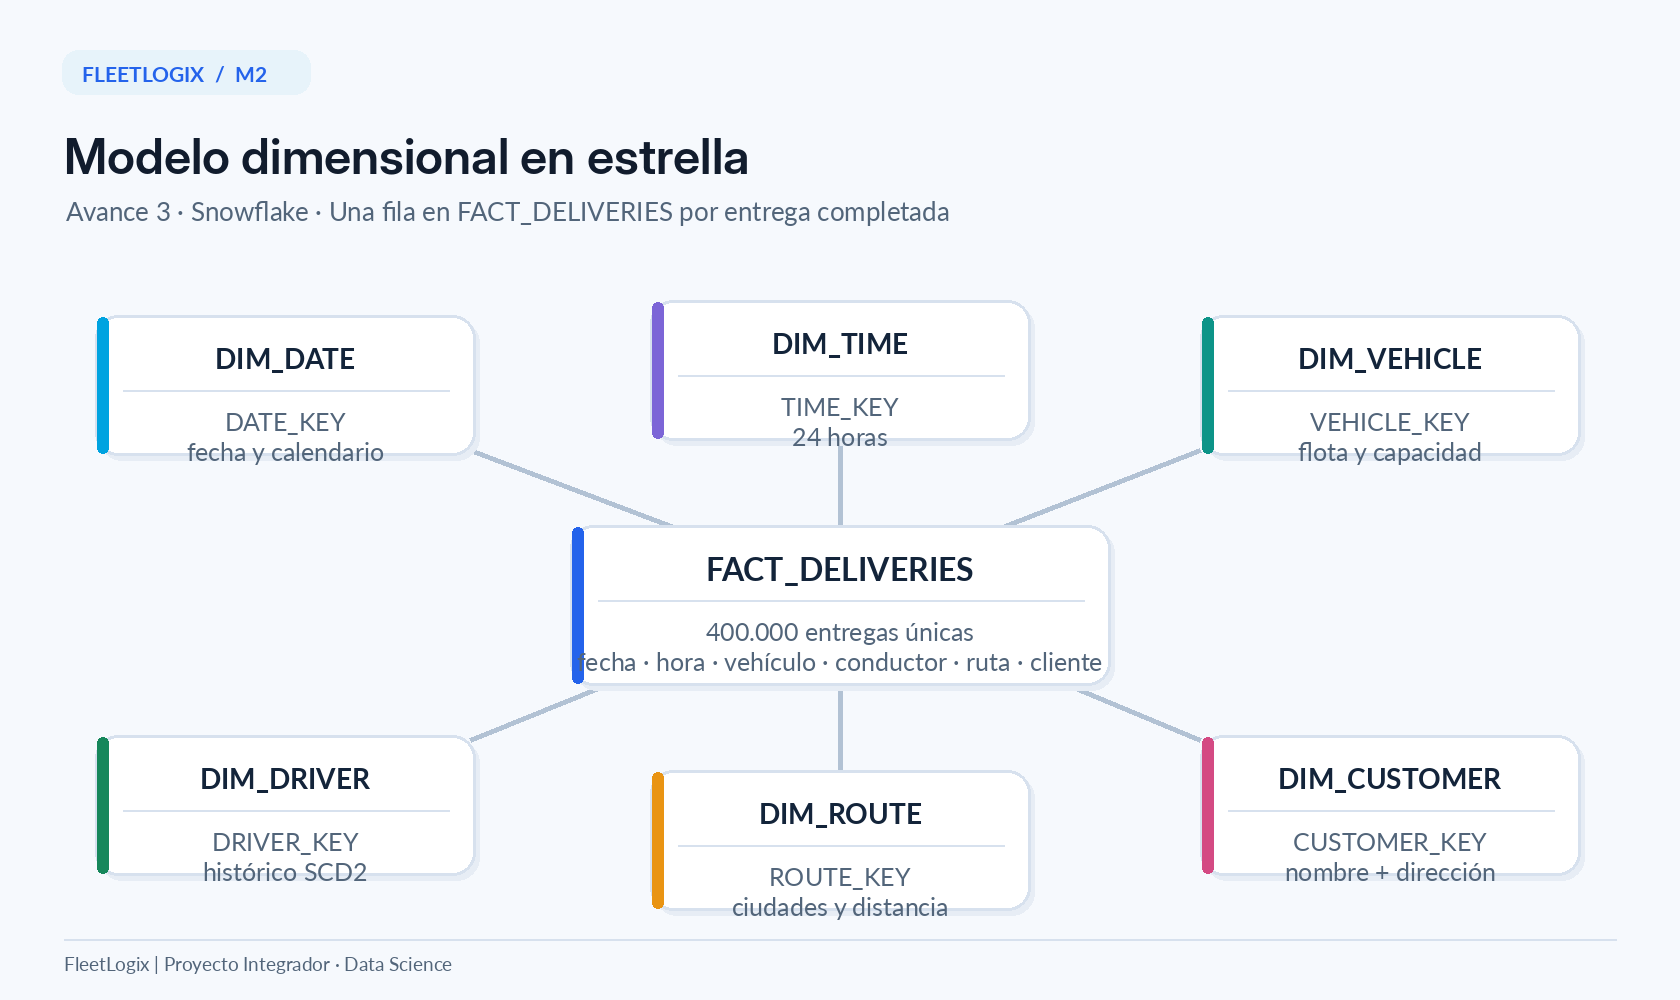

In [ ]:
# Figura incorporada como salida permanente del notebook.
# No hace falta ejecutar esta celda para ver el diagrama.

## 4. Infraestructura en Snowflake

| Componente | Configuración utilizada |
|---|---|
| Cuenta | Cuenta Snowflake propia del proyecto |
| Base de datos | `FLEETLOGIX_DW` |
| Esquema | `ANALYTICS` |
| Warehouse | `COMPUTE_WH` |
| Tabla central | `FACT_DELIVERIES` |
| Dimensiones | Seis dimensiones |
| Objetos auxiliares | `STG_DRIVER_SNAPSHOT`, `AGG_ENTREGAS_HORA`, `SEQ_DRIVER_VERSION`, vistas y procedimiento |

El archivo [`04_dimensional_model.sql`](04_dimensional_model.sql) documenta el **DDL recuperado del esquema real** mediante `GET_DDL('SCHEMA', 'FLEETLOGIX_DW.ANALYTICS', TRUE)`. Las operaciones `CREATE OR REPLACE` sobre tablas/esquema se adaptaron de forma preventiva para evitar una sustitución accidental si alguien abre ese archivo. **No se debe ejecutar indiscriminadamente sobre una base poblada ni interpretarlo como un script de despliegue completo**: no incluye todos los permisos, datos iniciales ni configuraciones de retención.

### Escalabilidad

Snowflake separa almacenamiento y cómputo y ofrece suspensión y reanudación automáticas de warehouses. **No se ha documentado todavía una consulta de configuración que confirme los parámetros exactos de escalado y `AUTO_SUSPEND` de `COMPUTE_WH`**. No se afirma que este warehouse tenga un modo multiclúster específico sin evidencia.

## 5. Proceso ETL: PostgreSQL → Python → Snowflake

```mermaid
flowchart LR
    P[("PostgreSQL<br/>fleetlogix")] --> E["Python ETL<br/>05_etl_pipeline.py"]
    E --> DI["Dimensiones"]
    E --> FA["FACT_DELIVERIES"]
    P --> S["07_driver_scd2.py<br/>Detectar cambios"]
    S --> DI
    FA --> PR["SP_REFRESH_AGGREGATES()"]
    PR --> AG["AGG_ENTREGAS_HORA"]
    AU["06_etl_automation.py<br/>02:00 (si está activo)"] -.-> E
    AU -.-> S
    AU -.-> PR
```

### 5.1. Extracción

El pipeline usa `psycopg2` para leer las tablas PostgreSQL. La extracción de hechos combina `deliveries`, `trips` y `routes`, filtra `delivery_status = 'delivered'` y requiere marcas temporales válidas para medir duración. La lectura de las entregas se realiza por lotes para no necesitar cargar todas las filas simultáneamente en memoria.

### 5.2. Transformación

- Normalización de campos y claves requeridas por Snowflake.
- Generación determinística de `CUSTOMER_KEY` mediante SHA-256.
- Cálculo de `DATE_KEY` a partir de la fecha real de entrega y `TIME_KEY` a partir de su hora.
- Rechazo de duraciones negativas o mayores de 30 días, conforme a la regla del script.
- Distribución proporcional de distancia y combustible del viaje entre sus entregas.
- Asignación de `DRIVER_KEY` por versión histórica y fecha de entrega en el **script revisado**; la lógica se ha comprobado localmente, pero no con una modificación histórica real en el entorno Snowflake.

### 5.3. Carga e idempotencia

El pipeline sube lotes con `write_pandas` a tablas temporales y utiliza `MERGE` para evitar insertar de nuevo un identificador ya existente. En `FACT_DELIVERIES`, la carga sobre un `DELIVERY_ID` existente no lo vuelve a insertar. En las dimensiones básicas se preservan las claves existentes mediante la misma estrategia general.

**Importante:** la existencia de `MERGE` fundamenta el diseño idempotente; para demostrarlo formalmente ante un evaluador todavía sería conveniente documentar una segunda corrida con el conteo anterior y posterior.

### 5.4. Comandos del proyecto

Ejecutar **desde la carpeta que contiene los tres scripts**:

```powershell
py 05_etl_pipeline.py --dimensions  # carga dimensiones
py 05_etl_pipeline.py --facts       # carga hechos
py 05_etl_pipeline.py --verify      # solo consulta conteos
py 07_driver_scd2.py               # previsualiza cambios, sin aplicar
py 07_driver_scd2.py --apply       # aplica historial SCD2
py 06_etl_automation.py --check     # comprobación sin escritura
py 06_etl_automation.py --once      # ejecuta el encadenamiento completo (con escritura)
py 06_etl_automation.py             # agenda a las 02:00 mientras siga activo
```

> **Seguridad al reproducir:** `--dimensions`, `--facts`, `--apply` y `--once` **sí escriben en Snowflake**. No deben lanzarse para inspeccionar el repositorio. Los modos `--verify` y `--check` son apropiados para consultas de comprobación.

### Flujo ETL — figura incorporada

Se representa la secuencia propuesta/implementada entre PostgreSQL, scripts Python y Snowflake; la ejecución automática nocturna aún requiere una prueba integral.

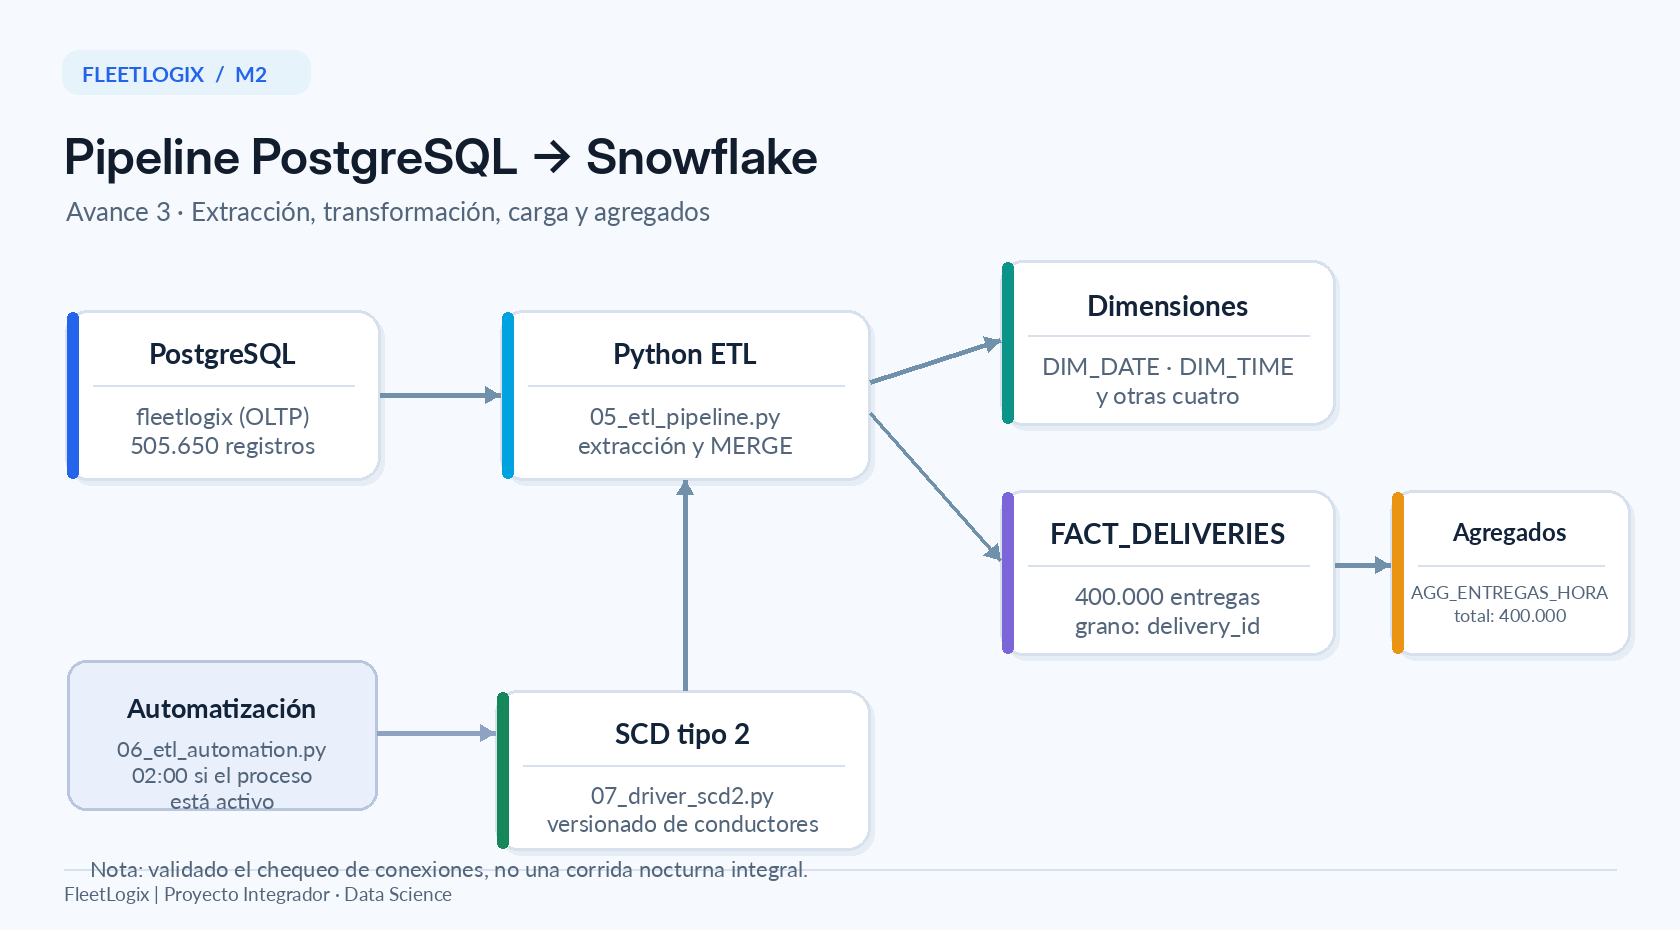

In [ ]:
# Figura incorporada como salida permanente del notebook.
# No hace falta ejecutar esta celda para ver el diagrama.

### Comprobación reproducible de los scripts (solo lectura)

La siguiente celda valida la sintaxis de los scripts **entregados por separado** en `2. Scripts`. No realiza operaciones de escritura en PostgreSQL ni Snowflake. El resultado dependerá de la carpeta desde donde se abra el notebook.

In [ ]:
# Inspección local y segura de los tres scripts entregados.
# Solo lee el texto de los archivos y valida su sintaxis; NO se conecta a bases.
from pathlib import Path
import ast

scripts_dir = Path.cwd()
# Compatible con ejecución desde 1. Notebooks o desde la raíz de la entrega.
candidatos = [
    scripts_dir / "2. Scripts",
    scripts_dir.parent / "2. Scripts",
    scripts_dir.parent.parent / "2. Scripts",
    scripts_dir,
]
carpeta_scripts = next((p for p in candidatos if (p / "05_etl_pipeline.py").is_file()), None)
archivos = ["05_etl_pipeline.py", "06_etl_automation.py", "07_driver_scd2.py"]

if carpeta_scripts is None:
    print("No se encontraron los scripts en la ruta de ejecución actual.")
    print("Se entregan por separado en la carpeta '2. Scripts'; no se modifica ningún dato.")
else:
    for nombre in archivos:
        ruta = carpeta_scripts / nombre
        if not ruta.exists():
            print(f"FALTA: {nombre}")
            continue
        arbol = ast.parse(ruta.read_text(encoding="utf-8"), filename=nombre)
        funciones = [x.name for x in arbol.body if isinstance(x, (ast.FunctionDef, ast.AsyncFunctionDef))]
        print(f"OK sintaxis: {nombre} | funciones definidas: {len(funciones)}")


## 6. Resultados observados de carga

Los siguientes conteos fueron verificados en nuestro entorno Snowflake durante la ejecución del Avance 3:

| Objeto | Filas verificadas |
|---|---:|
| `DIM_DATE` | 4.018 |
| `DIM_TIME` | 24 |
| `DIM_VEHICLE` | 200 |
| `DIM_DRIVER` | 400 |
| `DIM_ROUTE` | 50 |
| `DIM_CUSTOMER` | 399.998 |
| **`FACT_DELIVERIES`** | **400.000** |

Las 400.000 filas de `FACT_DELIVERIES` corresponden a **entregas completadas** incorporadas en este entorno; no se deben extrapolar estos resultados a otros proyectos que utilicen otra versión del dataset.

### 6.1. Controles de calidad realizados

| Control | Resultado observado |
|---|---:|
| Filas en `FACT_DELIVERIES` | 400.000 |
| `DELIVERY_ID` distintos | 400.000 |
| Duraciones negativas | 0 |
| Claves `DATE_KEY` nulas | 0 |
| Claves `VEHICLE_KEY` nulas | 0 |
| Claves `DRIVER_KEY` nulas | 0 |
| Total agregado de entregas en `AGG_ENTREGAS_HORA` | 400.000 |

Estas pruebas comprueban unicidad y ausencia de nulos **en los campos citados**. No equivalen a una prueba exhaustiva de todos los atributos, relaciones, pesos, consumos o calidad de los datos de origen.

### 6.2. SQL de validación reproducible (solo lectura)

```sql
USE DATABASE FLEETLOGIX_DW;
USE SCHEMA ANALYTICS;

SELECT COUNT(*) AS TOTAL_ENTREGAS,
       COUNT(DISTINCT DELIVERY_ID) AS ENTREGAS_UNICAS,
       COUNT_IF(DELIVERY_DURATION_MINUTES < 0) AS DURACIONES_NEGATIVAS,
       COUNT_IF(DATE_KEY IS NULL) AS FECHAS_NULAS,
       COUNT_IF(VEHICLE_KEY IS NULL) AS VEHICULOS_NULOS,
       COUNT_IF(DRIVER_KEY IS NULL) AS CONDUCTORES_NULOS
FROM FACT_DELIVERIES;

SELECT 'DIM_DATE' AS TABLA, COUNT(*) AS FILAS FROM DIM_DATE
UNION ALL SELECT 'DIM_TIME', COUNT(*) FROM DIM_TIME
UNION ALL SELECT 'DIM_VEHICLE', COUNT(*) FROM DIM_VEHICLE
UNION ALL SELECT 'DIM_DRIVER', COUNT(*) FROM DIM_DRIVER
UNION ALL SELECT 'DIM_ROUTE', COUNT(*) FROM DIM_ROUTE
UNION ALL SELECT 'DIM_CUSTOMER', COUNT(*) FROM DIM_CUSTOMER
UNION ALL SELECT 'FACT_DELIVERIES', COUNT(*) FROM FACT_DELIVERIES;

SELECT SUM(TOTAL_ENTREGAS) AS TOTAL_PRECALCULADO
FROM AGG_ENTREGAS_HORA;
```

### 6.3. Consultas de negocio que habilita el modelo

**Entregas y puntualidad por ruta**:

```sql
SELECT r.ROUTE_CODE,
       r.ORIGIN_CITY,
       r.DESTINATION_CITY,
       COUNT(*) AS ENTREGAS,
       ROUND(100.0 * AVG(IFF(f.IS_ON_TIME, 1, 0)), 2) AS PUNTUALIDAD_PCT
FROM FLEETLOGIX_DW.ANALYTICS.FACT_DELIVERIES f
JOIN FLEETLOGIX_DW.ANALYTICS.DIM_ROUTE r
  ON f.ROUTE_KEY = r.ROUTE_KEY
GROUP BY r.ROUTE_CODE, r.ORIGIN_CITY, r.DESTINATION_CITY
ORDER BY ENTREGAS DESC;
```

**Consumo y distancia asignados por tipo de vehículo**:

```sql
SELECT v.VEHICLE_TYPE,
       COUNT(*) AS ENTREGAS,
       ROUND(SUM(f.DISTANCE_KM), 2) AS KM_ASIGNADOS,
       ROUND(SUM(f.FUEL_CONSUMED_LITERS), 2) AS LITROS_ASIGNADOS
FROM FLEETLOGIX_DW.ANALYTICS.FACT_DELIVERIES f
JOIN FLEETLOGIX_DW.ANALYTICS.DIM_VEHICLE v
  ON f.VEHICLE_KEY = v.VEHICLE_KEY
GROUP BY v.VEHICLE_TYPE
ORDER BY ENTREGAS DESC;
```

**Volumen por fecha y hora**:

```sql
SELECT d.FULL_DATE, a.TIME_KEY AS HORA, SUM(a.TOTAL_ENTREGAS) AS ENTREGAS
FROM FLEETLOGIX_DW.ANALYTICS.AGG_ENTREGAS_HORA a
JOIN FLEETLOGIX_DW.ANALYTICS.DIM_DATE d ON a.DATE_KEY = d.DATE_KEY
GROUP BY d.FULL_DATE, a.TIME_KEY
ORDER BY d.FULL_DATE DESC, HORA;
```

*Estas son consultas reproducibles para demostrar el modelo. Sus resultados numéricos por categoría no se incluyen porque no se ejecutaron ni registraron como evidencia en esta entrega.*

### Volumen de datos — visualización de los conteos documentados

Estos valores proceden de las comprobaciones **ya realizadas** y consignadas arriba; la figura no representa una conexión nueva a Snowflake.

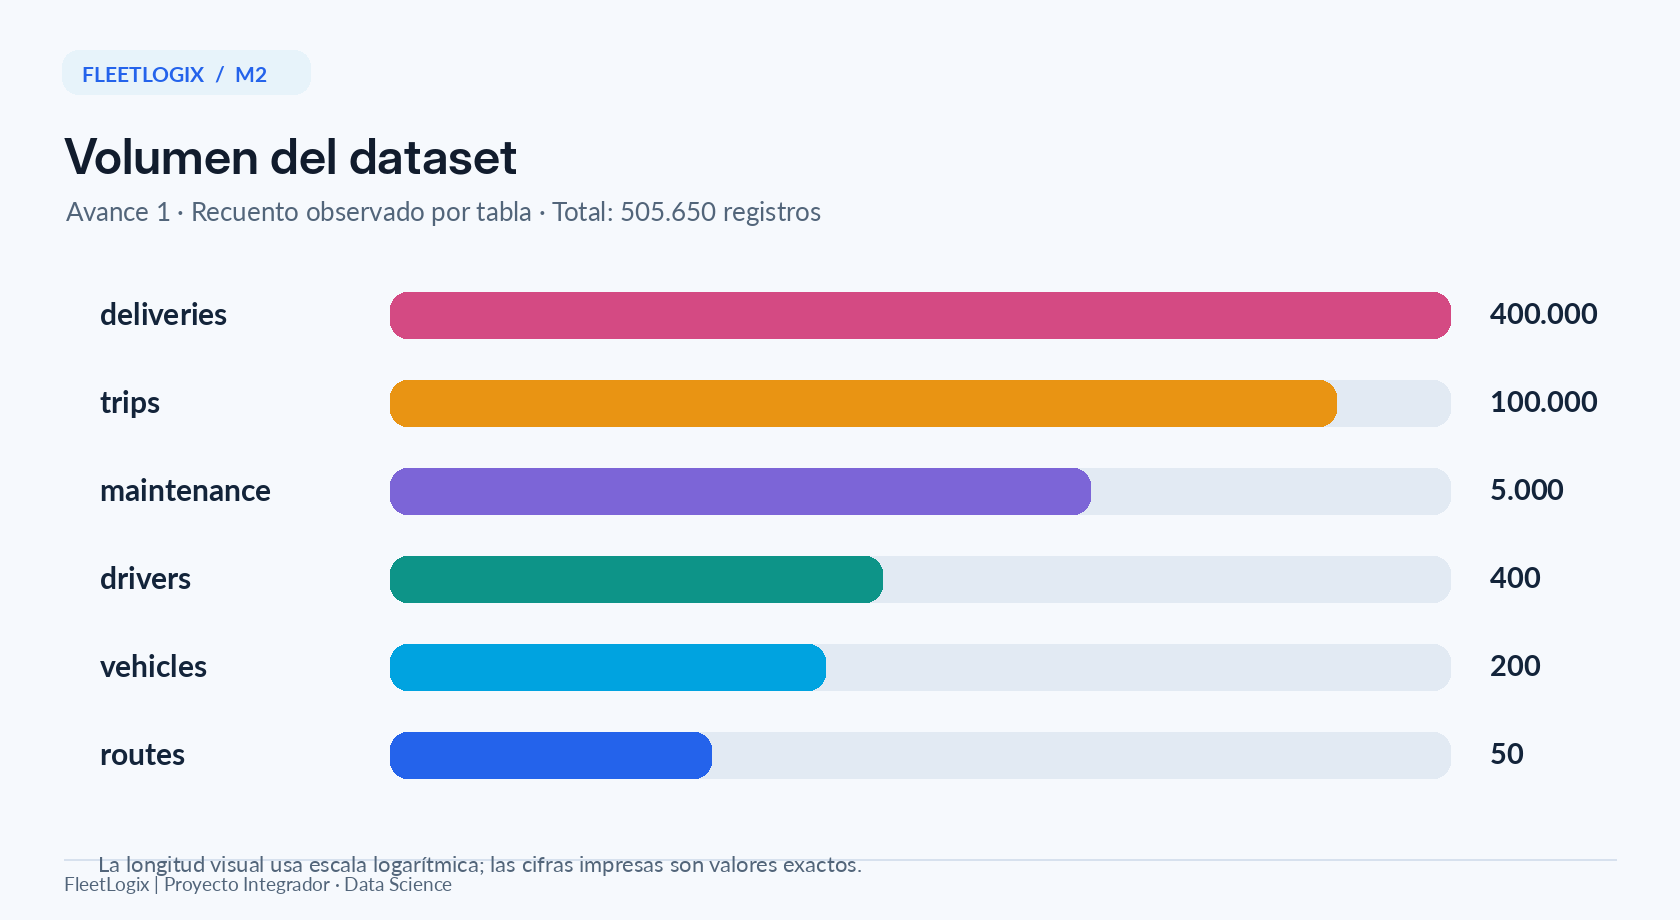

In [ ]:
# Figura incorporada como salida permanente del notebook.
# No hace falta ejecutar esta celda para ver el diagrama.

### Demostración ejecutable: transformación de métricas del ETL

La prueba siguiente utiliza **dos entregas simuladas**, solamente para reproducir la regla de reparto proporcional y verificar que los totales del viaje se conservan. **No sustituye una conciliación real en Snowflake.**

In [1]:
# Ejemplo reproducible de transformación local: reparto por peso.
# DATOS SIMULADOS PARA DEMOSTRAR LA REGLA, no filas extraídas de FleetLogix.
from math import isclose

entregas_ejemplo = [
    {"delivery_id": "E1", "peso_kg": 10},
    {"delivery_id": "E2", "peso_kg": 30},
]
km_viaje = 120.0
litros_viaje = 24.0
peso_total = sum(e["peso_kg"] for e in entregas_ejemplo)
resultado = [
    {
        "delivery_id": e["delivery_id"],
        "distancia_asignada_km": km_viaje * e["peso_kg"] / peso_total,
        "combustible_asignado_l": litros_viaje * e["peso_kg"] / peso_total,
    }
    for e in entregas_ejemplo
]
assert isclose(sum(x["distancia_asignada_km"] for x in resultado), km_viaje)
assert isclose(sum(x["combustible_asignado_l"] for x in resultado), litros_viaje)
for fila in resultado:
    print(fila)
print("Prueba local OK: los totales se conservan sin duplicar km ni combustible.")


{'delivery_id': 'E1', 'distancia_asignada_km': 30.0, 'combustible_asignado_l': 6.0}
{'delivery_id': 'E2', 'distancia_asignada_km': 90.0, 'combustible_asignado_l': 18.0}
Prueba local OK: los totales se conservan sin duplicar km ni combustible.


## 7. Historial de conductores: Slowly Changing Dimension Tipo 2

El modelo `DIM_DRIVER` contiene `DRIVER_ID` (identificador natural), `DRIVER_KEY` (clave de la versión), `VALID_FROM`, `VALID_TO` e `IS_CURRENT`.

**Diseño:** si un atributo relevante de un conductor cambia, la versión anterior pasa a `IS_CURRENT = FALSE` y se cierra su intervalo de vigencia; se inserta otra fila con una nueva `DRIVER_KEY`, manteniendo intacta la versión anterior. `SEQ_DRIVER_VERSION` provee claves para nuevas versiones. El snapshot `STG_DRIVER_SNAPSHOT` conserva la última extracción para control del estado observado.

**Validaciones realizadas:**

- Extracción de los 400 conductores del origen PostgreSQL.
- Comparación con el estado de Snowflake: **0 cambios detectados**.
- Ejecución de `07_driver_scd2.py --apply` sin errores, actualizando el snapshot.
- Recuento de **400 versiones actuales** y **ninguna versión histórica adicional creada** en esa ejecución.

**Alcance de la evidencia:** como no se introdujo un cambio real de conductor, todavía no se verificó en la cuenta Snowflake la creación de una segunda versión ni la unión histórica de hechos tras una modificación. El pipeline revisado contempla selección por fecha, pero el resultado final aún requiere una prueba de integración si ese escenario es evaluado.

### Demostración de lógica SCD2 sin escrituras

Este caso ficticio ilustra una versión histórica y una vigente. En nuestro Snowflake **se comprobaron 0 cambios reales**; no se presenta esta simulación como evidencia de una actualización real.

In [2]:
# Demostración SCD2 en memoria, sin modificar tablas.
# Se simula el cambio de licencia de un conductor ficticio.
versiones = [
    {"driver_id": "SIM-01", "licencia": "A1", "valid_from": "2026-01-01",
     "valid_to": None, "is_current": True}
]
licencia_nueva = "B2"
if versiones[-1]["licencia"] != licencia_nueva:
    versiones[-1]["valid_to"] = "2026-11-17"
    versiones[-1]["is_current"] = False
    versiones.append({"driver_id": "SIM-01", "licencia": licencia_nueva,
                     "valid_from": "2026-11-18", "valid_to": None, "is_current": True})
assert len(versiones) == 2
assert sum(v["is_current"] for v in versiones) == 1
for v in versiones:
    print(v)
print("Prueba conceptual SCD2 OK (datos simulados).")


{'driver_id': 'SIM-01', 'licencia': 'A1', 'valid_from': '2026-01-01', 'valid_to': '2026-11-17', 'is_current': False}
{'driver_id': 'SIM-01', 'licencia': 'B2', 'valid_from': '2026-11-18', 'valid_to': None, 'is_current': True}
Prueba conceptual SCD2 OK (datos simulados).


## 8. Métricas precalculadas

Se implementó la tabla `AGG_ENTREGAS_HORA`, que agrupa hechos por `DATE_KEY`, `TIME_KEY` y `DRIVER_KEY`. Sus medidas son:

- `TOTAL_ENTREGAS`.
- `DURACION_PROMEDIO_MIN`.
- `DISTANCIA_TOTAL_KM`.
- `COMBUSTIBLE_TOTAL_L`.

El procedimiento `SP_REFRESH_AGGREGATES()` recalcula esta tabla desde `FACT_DELIVERIES`. **Su creación, invocación y suma de 400.000 entregas fueron comprobadas**. El SQL incluye `COPY GRANTS` al sustituir el agregado, y se verificó que se conserva el permiso de lectura del rol operativo.

La dimensión tiempo trabaja a resolución **de hora (24 valores)**. No atribuye minutos exactos a la clave `TIME_KEY`.

## 9. Seguridad y gobierno de datos

### 9.1. Separación por roles

Se crearon las siguientes **vistas seguras** (`SECURE VIEW`):

| Vista | Audiencia | Alcance |
|---|---|---|
| `VW_OPERACIONES` | `FLEETLOGIX_OPERACIONES` | Detalle operativo de entregas |
| `VW_VENTAS` | `FLEETLOGIX_VENTAS` | Agregación por fecha y ruta |

Los roles y permisos fueron configurados y revisados. **No se documentó todavía una prueba completa de denegación/permiso usando exclusivamente cada rol**; la existencia de los grants no debe confundirse con esa prueba.

**Restricción importante:** el origen no ofrece precios ni ingresos. Por eso `VW_VENTAS` no inventa facturación; la columna agregada de ingresos procede de `REVENUE_ESTIMATED`, que en los datos cargados permanece `NULL`.

### 9.2. Time Travel

Se confirmó una configuración de **30 días de retención** sobre `FACT_DELIVERIES`. Esto permite plantear recuperación histórica dentro de la ventana habilitada por la edición y configuración de Snowflake. **Se verificó la retención, pero no se registró una comparación temporal real mediante `AT` o `BEFORE` en esta entrega.**

Consulta de inspección:

```sql
SHOW TABLES LIKE 'FACT_DELIVERIES' IN SCHEMA FLEETLOGIX_DW.ANALYTICS;
```

### 9.3. Autenticación del ETL

La conexión a Snowflake usa el usuario de servicio `FLEETLOGIX_ETL_SVC`, rol `FLEETLOGIX_ETL_ROLE` y autenticación con clave RSA. La clave privada se almacena **fuera del proyecto**, en una carpeta local protegida; no se distribuye por GitHub. PostgreSQL utiliza la configuración local `pgpass.conf` para evitar solicitudes interactivas.

La autenticación no interactiva con ambas bases fue comprobada. El script `06_etl_automation.py --check` terminó con **`CHECK OK`**, que significa que las conexiones y consultas básicas de lectura respondieron correctamente. **No significa que la cadena completa de carga haya sido ejecutada.**

## 10. Automatización nocturna

El flujo planeado para las **02:00, hora local del equipo Windows**, es:

1. Actualizar dimensiones (`05_etl_pipeline.py --dimensions`).
2. Detectar y aplicar cambios de conductores (`07_driver_scd2.py --apply`).
3. Cargar hechos (`05_etl_pipeline.py --facts`).
4. Refrescar `AGG_ENTREGAS_HORA` llamando al procedimiento Snowflake.

`06_etl_automation.py` implementa ese orden, detiene la secuencia si falla una etapa y ofrece modos `--check` y `--once`.

**Situación comprobada:** la prueba no destructiva `--check` devolvió `CHECK OK`. **Pendiente:** ejecución real `--once` con permisos de escritura, observación del comportamiento frente a fallos y despliegue de un programador persistente. La librería `schedule` **no ejecuta tareas cuando el script está cerrado o la computadora está suspendida**. En producción sería necesario Windows Task Scheduler, un servidor o un orquestador apropiado.

## 11. Estado de las verificaciones

| Requisito | Estado sustentado por evidencias |
|---|---|
| Modelo en estrella, esquema y tablas | **Implementado**; DDL exportado de Snowflake |
| Carga inicial y conteos | **Comprobados** en el entorno del proyecto |
| Unicidad de `DELIVERY_ID` y nulos clave | **Comprobados** en los controles listados |
| Distribución de distancia y combustible | **Implementada** en Python; no se incluye conciliación monetaria |
| `AGG_ENTREGAS_HORA` | **Creado, actualizado y conteo conciliado** |
| Vistas seguras y grants | **Configurados**; no se adjunta matriz de pruebas negativas |
| Time Travel 30 días | **Retención comprobada**; consulta histórica no demostrada |
| SCD2 de conductores | **Ejecución sin cambios comprobada**; prueba de cambio real pendiente |
| Conectividad de cuenta de servicio | **Comprobada** |
| Automatización `--check` | **Comprobada**, solo lectura |
| Automatización `--once` y horario 02:00 | **Diseñada, no verificada de extremo a extremo ni desplegada** |
| Parámetros exactos de autoescalado | **No verificados** |
| Feriados de `DIM_DATE` | **No configurados con calendario oficial** |

La distinción anterior permite que el evaluador identifique qué resultados se obtuvieron realmente y qué funcionalidades permanecen como desarrollo o validación futura.

## 12. Archivos de la entrega

| Archivo | Contenido |
|---|---|
| [`04_dimensional_model.sql`](04_dimensional_model.sql) | DDL documental recuperado de Snowflake: tablas, vistas, secuencia y procedimiento |
| [`05_etl_pipeline.py`](05_etl_pipeline.py) | Extracción, transformación, cargas por lotes, `MERGE` y verificación de conteos |
| [`06_etl_automation.py`](06_etl_automation.py) | Comprobación de conexiones y coordinación del flujo diario |
| [`07_driver_scd2.py`](07_driver_scd2.py) | Detección de cambios de conductores y versionado SCD2 |
| `Avance_3_DataWarehouse_ACTUALIZADO.ipynb` | Notebook de documentación del Data Warehouse y las validaciones |
| `README_Avance3_FleetLogix_COMPLETO.md` | Este documento explicativo del Avance 3 |
| `.gitignore` | Exclusión de claves, contraseñas, entornos y archivos temporales |

**Nota sobre reproducibilidad:** el DDL extraído contiene definiciones de objetos, no una exportación de los 505.650 registros ni la configuración completa de cuentas, permisos y tareas. Para ejecutar todo desde cero se necesitan las tablas originales de PostgreSQL, un esquema preparado en Snowflake, los paquetes de Python y credenciales propias.

### Dependencias principales

```powershell
py -m pip install pandas psycopg2-binary "snowflake-connector-python[pandas]" schedule
```

No se incluyen contraseñas, claves privadas, tokens ni los datos personales del origen en este repositorio.

## 13. Limitaciones y próximas mejoras

- **Información comercial:** sin tarifas ni precios en origen no es correcto presentar ingresos o rentabilidad como datos observados.
- **Calendario:** los feriados necesitan elegir país y fuente oficial; `IS_HOLIDAY` no debe interpretarse como verificado.
- **Clientes:** la identificación por nombre + dirección puede unir o separar identidades de forma imperfecta.
- **Temporalidad:** `DIM_TIME` funciona por hora; un análisis por minuto necesita otra granularidad.
- **Historia SCD2:** falta una prueba controlada de modificación real, incluida la conciliación temporal de hechos.
- **Orquestación:** falta validar el flujo completo con el usuario de servicio y programarlo de manera persistente.
- **Gobierno y pruebas:** sería útil adjuntar capturas de permisos permitidos/denegados y una consulta histórica Time Travel.
- **Escalabilidad:** la configuración efectiva del warehouse debe inspeccionarse antes de atribuirle escalado automático multiclúster.

## 14. Conclusión

En este avance se construyó un **Data Warehouse dimensional en Snowflake**, alimentado desde PostgreSQL por Python, con **400.000 hechos de entregas** y seis dimensiones. Se verificaron conteos, unicidad de entregas, controles principales de calidad, actualización de métricas agregadas, controles de acceso configurados y conexión no interactiva de servicio.

El proyecto establece una base analítica útil para estudiar la operación logística. La documentación distingue explícitamente las capacidades **implementadas y comprobadas** de las funcionalidades cuya **validación final o automatización persistente aún está pendiente**. Este enfoque evita atribuir al sistema resultados que todavía no se han observado y permite continuar la evolución del proyecto hacia una arquitectura cloud en el Avance 4.